### Data

In [1]:
import torch
import pandas as pd

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

In [3]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
sample_sub = pd.read_csv('sample_submission.csv')

print(train.shape)
print(test.shape)
train.head(10)

(1460, 81)
(1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000
6,7,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,307000
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
8,9,50,RM,51.0,6120,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900
9,10,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2008,WD,Normal,118000


In [4]:
test.head(10)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal
5,1466,60,RL,75.0,10000,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal
6,1467,20,RL,NaN,7980,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,GdPrv,Shed,500,3,2010,WD,Normal
7,1468,60,RL,63.0,8402,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal
8,1469,20,RL,85.0,10176,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,2,2010,WD,Normal
9,1470,20,RL,70.0,8400,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,4,2010,WD,Normal


In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [6]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1459 entries, 0 to 1458
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1459 non-null   int64  
 1   MSSubClass     1459 non-null   int64  
 2   MSZoning       1455 non-null   object 
 3   LotFrontage    1232 non-null   float64
 4   LotArea        1459 non-null   int64  
 5   Street         1459 non-null   object 
 6   Alley          107 non-null    object 
 7   LotShape       1459 non-null   object 
 8   LandContour    1459 non-null   object 
 9   Utilities      1457 non-null   object 
 10  LotConfig      1459 non-null   object 
 11  LandSlope      1459 non-null   object 
 12  Neighborhood   1459 non-null   object 
 13  Condition1     1459 non-null   object 
 14  Condition2     1459 non-null   object 
 15  BldgType       1459 non-null   object 
 16  HouseStyle     1459 non-null   object 
 17  OverallQual    1459 non-null   int64  
 18  OverallC

In [7]:
train.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

In [8]:
test.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           4
LotFrontage      227
LotArea            0
                ... 
MiscVal            0
MoSold             0
YrSold             0
SaleType           1
SaleCondition      0
Length: 80, dtype: int64

Target Variable Analysis

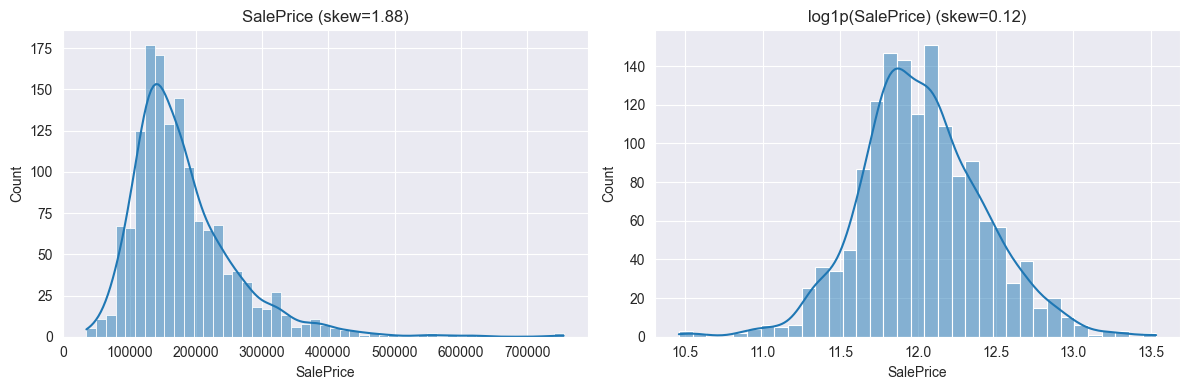

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

fig, axes = plt.subplots(1, 2, figsize=(12, 4))   #fig, axes = plt.subplots(width, height, figsize=(12, 4))
#Histogram of Original SalePrice
#KDE = Kernel Density Estimation
sns.histplot(train['SalePrice'], kde=True, ax=axes[0])
axes[0].set_title(f"SalePrice (skew={train['SalePrice'].skew():.2f})")

#Log transformation on SalePrice
log_price = np.log1p(train['SalePrice'])
sns.histplot(log_price, kde=True, ax=axes[1])
axes[1].set_title(f"log1p(SalePrice) (skew={log_price.skew():.2f})")
plt.tight_layout()
plt.show()

Train and Test Combine

In [10]:
train_ID = train['Id']
test_ID = test['Id']

n_train = train.shape[0]
n_test = test.shape[0]

y_train = np.log1p(train['SalePrice']).reset_index(drop=True)

all_data = pd.concat([train.drop(['Id', 'SalePrice'], axis=1),
                       test.drop(['Id'], axis=1)]).reset_index(drop=True)

print('all_data shape:', all_data.shape)

all_data shape: (2919, 79)


Missing Value Handling

In [11]:
# Categorical columns where NaN means "None"
none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
             'MasVnrType']
for col in none_cols:
    all_data[col] = all_data[col].fillna('None')

# Numeric columns where NaN means "0 / none"
zero_cols = ['GarageYrBlt', 'GarageArea', 'GarageCars',
             'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
             'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']
for col in zero_cols:
    all_data[col] = all_data[col].fillna(0)

# LotFrontage: Fill with the median of the same neighborhood.
all_data['LotFrontage'] = all_data.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)
all_data['LotFrontage'] = all_data['LotFrontage'].fillna(all_data['LotFrontage'].median())

# Utilities drop (almost all have the same value)
all_data = all_data.drop(['Utilities'], axis=1)

# For the rest: categorical -> mode, numeric -> median.
import pandas.api.types as ptypes
for col in all_data.columns:
    if all_data[col].isnull().sum() > 0:
        if ptypes.is_numeric_dtype(all_data[col]):
            all_data[col] = all_data[col].fillna(all_data[col].median())
        else:
            all_data[col] = all_data[col].fillna(all_data[col].mode()[0])

print('Remaining missing values:', all_data.isnull().sum().sum())

Remaining missing values: 0


Feature Engineering

In [12]:
all_data['MSSubClass'] = all_data['MSSubClass'].astype(str)

all_data['TotalSF'] = all_data['TotalBsmtSF'] + all_data['1stFlrSF'] + all_data['2ndFlrSF']

all_data['TotalBath'] = (all_data['FullBath'] + 0.5 * all_data['HalfBath'] +
                          all_data['BsmtFullBath'] + 0.5 * all_data['BsmtHalfBath'])

all_data['HouseAge'] = all_data['YrSold'] - all_data['YearBuilt']
all_data['RemodAge'] = all_data['YrSold'] - all_data['YearRemodAdd']
all_data['IsRemodeled'] = (all_data['YearBuilt'] != all_data['YearRemodAdd']).astype(int)

all_data['HasPool'] = (all_data['PoolArea'] > 0).astype(int)
all_data['Has2ndFloor'] = (all_data['2ndFlrSF'] > 0).astype(int)
all_data['HasGarage'] = (all_data['GarageArea'] > 0).astype(int)
all_data['HasBsmt'] = (all_data['TotalBsmtSF'] > 0).astype(int)
all_data['HasFireplace'] = (all_data['Fireplaces'] > 0).astype(int)

all_data['HouseAge'] = all_data['HouseAge'].clip(lower=0)
all_data['RemodAge'] = all_data['RemodAge'].clip(lower=0)

print('Shape after feature engineering:', all_data.shape)

Shape after feature engineering: (2919, 88)


In [13]:
from scipy.special import boxcox1p
from scipy.stats import skew

# I will transform only the "truly continuous" features (such as area or monetary values)—
# excluding binary flags (0/1), ordinal quality scores (0-5), or count/year-type columns,
# because transforming these actually harms tree-based models (as proven in previous tests).
continuous_cols = ['LotFrontage', 'LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
                    'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
                    'GrLivArea', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch',
                    '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'TotalSF']
continuous_cols = [c for c in continuous_cols if c in all_data.columns]

skewed = all_data[continuous_cols].apply(lambda x: skew(x.dropna()))
high_skew = skewed[abs(skewed) > 0.75]
print(f'{len(high_skew)} skewed continuous features found.')

# The original all_data remains unchanged (tree models will use this)
# Creating a separate transformed copy for Ridge
all_data_ridge = all_data.copy()
lam = 0.15
for feat in high_skew.index:   #Box-Cox transformation
    all_data_ridge[feat] = boxcox1p(all_data_ridge[feat], lam)

print('all_data       -> raw (for Random Forest, XGBoost, LightGBM)')
print('all_data_ridge -> skew-corrected (for Ridge only)')

19 skewed continuous features found.
all_data       -> raw (for Random Forest, XGBoost, LightGBM)
all_data_ridge -> skew-corrected (for Ridge only)


Categorical Encoding

In [14]:
qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5} #None, Poor, Fair, Typical/Average, good, Excellent,
ordinal_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
                'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']

def encode_categoricals(df):
    df = df.copy()
    for col in ordinal_cols:
        df[col] = df[col].map(qual_map).fillna(0).astype(int)
    df = pd.get_dummies(df, drop_first=True)
    return df

all_data_encoded = encode_categoricals(all_data)          # raw -> tree models
all_data_ridge_encoded = encode_categoricals(all_data_ridge)  # transformed -> Ridge

print('Final feature count (raw):', all_data_encoded.shape[1])
print('Final feature count (ridge):', all_data_ridge_encoded.shape[1])

Final feature count (raw): 252
Final feature count (ridge): 252


Outlier Removal + Split Back

In [15]:
# Raw version (tree models)
X_train_full = all_data_encoded.iloc[:n_train, :].reset_index(drop=True)
X_test = all_data_encoded.iloc[n_train:, :].reset_index(drop=True)

# Ridge version (skew-corrected)
X_train_full_r = all_data_ridge_encoded.iloc[:n_train, :].reset_index(drop=True)
X_test_r = all_data_ridge_encoded.iloc[n_train:, :].reset_index(drop=True)

outlier_mask = ~((X_train_full['GrLivArea'] > 4000) & (y_train < np.log1p(300000)))

X_train = X_train_full[outlier_mask].reset_index(drop=True)
X_train_r = X_train_full_r[outlier_mask].reset_index(drop=True)
y_train_clean = y_train[outlier_mask].reset_index(drop=True)

print('Before:', X_train_full.shape, '-> After outlier removal:', X_train.shape)

Before: (1460, 252) -> After outlier removal: (1458, 252)


Cross-Validation + Baseline (Ridge)

In [16]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import RobustScaler

n_folds = 5

"""
Round 1 -> Train: 2,3,4,5 | Validate: 1
Round 2 -> Train: 1,3,4,5 | Validate: 2
Round 3 -> Train: 1,2,4,5 | Validate: 3
Round 4 -> Train: 1,2,3,5 | Validate: 4
Round 5 -> Train: 1,2,3,4 | Validate: 5
"""
kf = KFold(n_folds, shuffle=True, random_state=42)

def rmse_cv(model, X, y):
    scores = -cross_val_score(model, X, y, scoring='neg_root_mean_squared_error', cv=kf)
    return scores

# Skew-corrected feature (X_train_r) is being used for Ridge.
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train_r)

ridge = Ridge(alpha=10)
scores = rmse_cv(ridge, X_train_scaled, y_train_clean)
print(f'Ridge baseline RMSE: {scores.mean():.4f} (+/- {scores.std():.4f})')

Ridge baseline RMSE: 0.1135 (+/- 0.0079)


Tree-based Models

In [17]:
!pip install xgboost lightgbm

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
import xgboost as xgb
import lightgbm as lgb

#Random Forest
rf = RandomForestRegressor(
    n_estimators=300, # It will create 300 decision tree
    max_depth=15,     # Each tree can have a maximum depth of 15 levels
    random_state=42,  #To reproduce the same result
    n_jobs=-1         # using all the computer's CPU cores
)
scores = rmse_cv(rf, X_train, y_train_clean)
print(f'RandomForest RMSE: {scores.mean():.4f} (+/- {scores.std():.4f})') #RMSE = Root Mean Square Error

#XGBoost
xgb_model = xgb.XGBRegressor(
    n_estimators=1000, #1000 boosting trees
    learning_rate=0.03,
    max_depth=4, #Each tree is at most 4 levels deep
    subsample=0.8, # Each tree will use 80% of the training data
    colsample_bytree=0.7, #It will use 70% of the features for each tree
    random_state=42,
    n_jobs=-1    # Using all CPU cores
)
scores = rmse_cv(xgb_model, X_train, y_train_clean) # Calculate the cross validation EMSE for XGBoost
print(f'XGBoost RMSE: {scores.mean():.4f} (+/- {scores.std():.4f})')

#LightGBM
lgb_model = lgb.LGBMRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    num_leaves=20,
    subsample=0.8,
    colsample_bytree=0.7,
    random_state=42,
    verbosity=-1 # It will display fewer unnecessary outputs/warnings.
)
scores = rmse_cv(lgb_model, X_train, y_train_clean)
print(f'LightGBM RMSE: {scores.mean():.4f} (+/- {scores.std():.4f})')

RandomForest RMSE: 0.1366 (+/- 0.0071)
XGBoost RMSE: 0.1182 (+/- 0.0075)
LightGBM RMSE: 0.1216 (+/- 0.0075)


Final Training + Blending

In [19]:
#X_train_scaled -> scaled training features
#y_train_clean -> target variable

ridge.fit(X_train_scaled, y_train_clean)
xgb_model.fit(X_train, y_train_clean)
lgb_model.fit(X_train, y_train_clean)

# Ridge is making predictions using the skew-corrected test set (X_test_r).
X_test_scaled = scaler.transform(X_test_r)

pred_ridge = ridge.predict(X_test_scaled)
pred_xgb = xgb_model.predict(X_test)
pred_lgb = lgb_model.predict(X_test)

final_log_pred = 0.45 * pred_ridge + 0.30 * pred_xgb + 0.25 * pred_lgb  # More weight because Ridge did the best in CV
final_pred = np.expm1(final_log_pred)

print('Prediction sample:', final_pred[:5])

Prediction sample: [121842.42796541 160508.33514045 185388.0971568  195334.86593899
 190515.10939945]


Submission File

In [20]:
submission = pd.DataFrame({
    'Id': test_ID,
    'SalePrice': final_pred
})
submission.to_csv('submission.csv', index=False)
submission.head()

,Id,SalePrice
0,1461,121842.427965
1,1462,160508.335140
2,1463,185388.097157
3,1464,195334.865939
4,1465,190515.109399


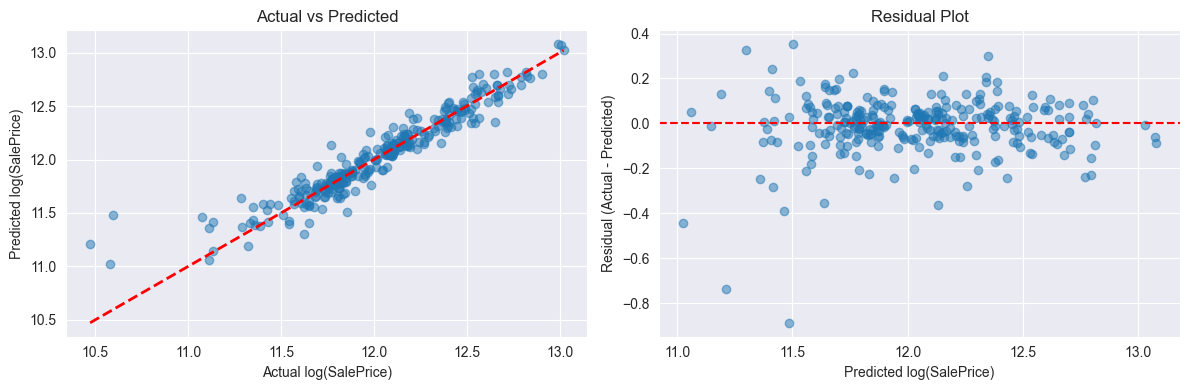

Validation RMSE (log scale): 0.1264
R² score: 0.9052  (1.0 = perfect, 0 = model no better than average guess)


In [21]:
from sklearn.model_selection import train_test_split

# I am splitting the training data once more just for checking purposes (this is not the final model; it is solely for visualization).
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train_clean, test_size=0.2, random_state=42)

check_model = lgb.LGBMRegressor(
    n_estimators=1000, learning_rate=0.03, num_leaves=20,
    subsample=0.8, colsample_bytree=0.7, random_state=42, verbosity=-1
)
check_model.fit(X_tr, y_tr)
val_pred = check_model.predict(X_val)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# ১. Actual vs Predicted (log scale) - perfect হলে সব points 45-degree line-এর উপর পড়বে
axes[0].scatter(y_val, val_pred, alpha=0.5)
axes[0].plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2)
axes[0].set_xlabel('Actual log(SalePrice)')
axes[0].set_ylabel('Predicted log(SalePrice)')
axes[0].set_title('Actual vs Predicted')

# ২. Residuals - It should be scattered randomly; the presence of any pattern is problematic.
residuals = y_val - val_pred
axes[1].scatter(val_pred, residuals, alpha=0.5)
axes[1].axhline(y=0, color='r', linestyle='--')
axes[1].set_xlabel('Predicted log(SalePrice)')
axes[1].set_ylabel('Residual (Actual - Predicted)')
axes[1].set_title('Residual Plot')

plt.tight_layout()
plt.show()

from sklearn.metrics import mean_squared_error, r2_score
val_rmse = mean_squared_error(y_val, val_pred) ** 0.5
val_r2 = r2_score(y_val, val_pred)
print(f'Validation RMSE (log scale): {val_rmse:.4f}')
print(f'R² score: {val_r2:.4f}  (1.0 = perfect, 0 = model no better than average guess)')

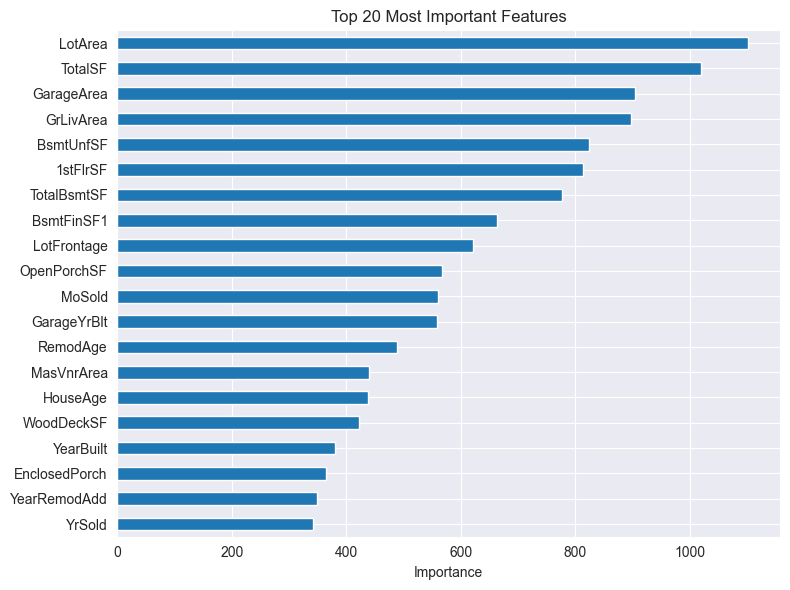

In [22]:
importances = pd.Series(check_model.feature_importances_, index=X_train.columns)
top20 = importances.sort_values(ascending=False).head(20)

plt.figure(figsize=(8, 6))
top20.sort_values().plot(kind='barh')
plt.title('Top 20 Most Important Features')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()